# Evaluating antigen specificity model

In [1]:
import itertools

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy import stats
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.models import PAEAggregator

In [2]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500
SEED = 123
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')

In [4]:
confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

In [5]:
with h5py.File('../data/processed/af3_af3_tcrmodel2_pae.h5', 'r') as fh:
    paes = torch.Tensor(fh['pae'][:])
    folds = fh['fold'][:]
    labels = fh['label'][:]

indices = np.arange(len(labels))

## Original

ROC-AUC: 0.6003333688888889


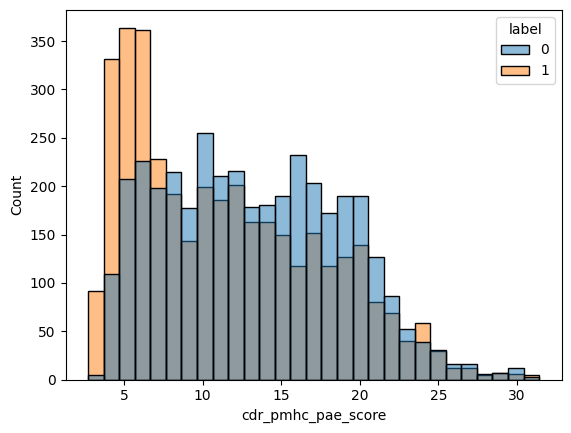

In [6]:
sns.histplot(confidence_scores, x='cdr_pmhc_pae_score', hue='label')
print('ROC-AUC:', 1 - roc_auc_score(confidence_scores['label'], confidence_scores['cdr_pmhc_pae_score']))
plt.show()

In [7]:
rng = np.random.default_rng(seed=SEED)

original_roc_auc_scores = []
for _ in range(NUM_SAMPLES):
    sample = confidence_scores.sample(SAMPLE_SIZE, random_state=rng)
    original_roc_auc_scores.append(1 - roc_auc_score(sample['label'], sample['cdr_pmhc_pae_score']))

## Untrained Aggregator Model

In [8]:
model = PAEAggregator(3120)
model.eval()

untrained_predictions = model(paes).cpu().detach().numpy()

ROC-AUC: 0.6003367466666667


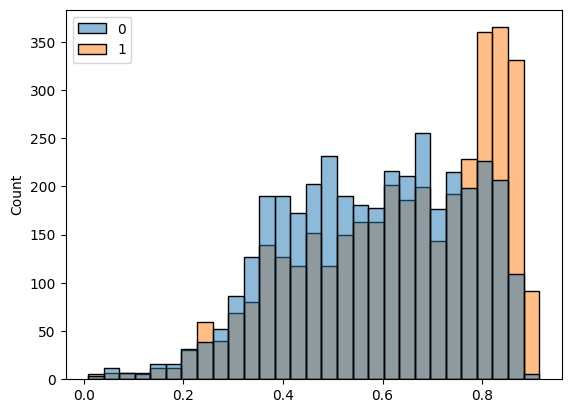

In [9]:
sns.histplot(x=untrained_predictions, hue=labels)
print('ROC-AUC:', roc_auc_score(labels, untrained_predictions))

In [10]:
rng = np.random.default_rng(seed=SEED)

untrained_roc_auc_scores = []
for _ in range(NUM_SAMPLES):
    sample_indices = rng.choice(indices, SAMPLE_SIZE)
    untrained_roc_auc_scores.append(roc_auc_score(labels[sample_indices], untrained_predictions[sample_indices]))

## Trained Aggregator

In [11]:
model = PAEAggregator(3120)
model.eval()

trained_predictions = []
trained_labels = []
for fold in np.unique(folds):
    model.load_state_dict(
        torch.load(
            f'../models/PAEAggregator_af3_af3_tcrmodel2/model_{fold}.pt',
            weights_only=True,
            map_location=torch.device('cpu'),
        )
    )
    trained_predictions.append(model(paes[folds == fold]).cpu().detach().numpy())
    trained_labels.append(labels[folds == fold])

trained_predictions = np.concatenate(trained_predictions)
trained_labels = np.concatenate(trained_labels)

ROC-AUC: 0.6033632


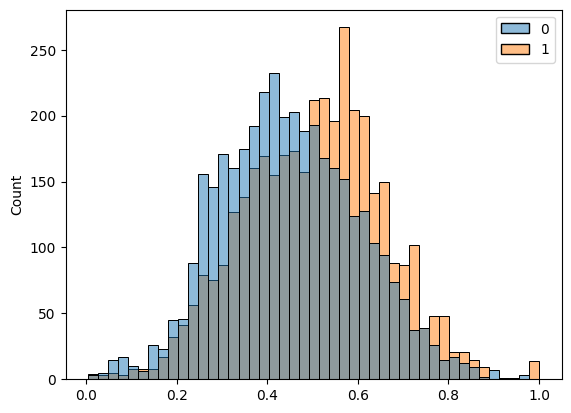

In [12]:
sns.histplot(x=trained_predictions, hue=trained_labels)
print('ROC-AUC:', roc_auc_score(trained_labels, trained_predictions))
plt.show()

In [13]:
rng = np.random.default_rng(seed=SEED)

trained_roc_auc_scores = []
for _ in range(NUM_SAMPLES):
    sample_indices = rng.choice(indices, SAMPLE_SIZE)
    trained_roc_auc_scores.append(roc_auc_score(trained_labels[sample_indices], trained_predictions[sample_indices]))

## Comparison

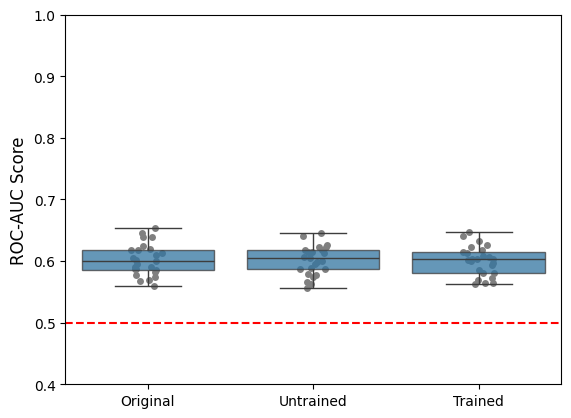

In [14]:
fig, ax = plt.subplots(1, 1)

sns.stripplot(
    data=[original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores], color='grey', ax=ax, zorder=1
)
sns.boxplot(
    data=[original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores],
    ax=ax,
    color='tab:blue',
    boxprops={'alpha': 0.75},
    zorder=2,
)

ax.axhline(0.5, color='red', linestyle='dashed')

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(['Original', 'Untrained', 'Trained'])

ax.set_ylim([0.4, 1.0])

ax.set_ylabel('ROC-AUC Score', fontsize=12)

plt.show()

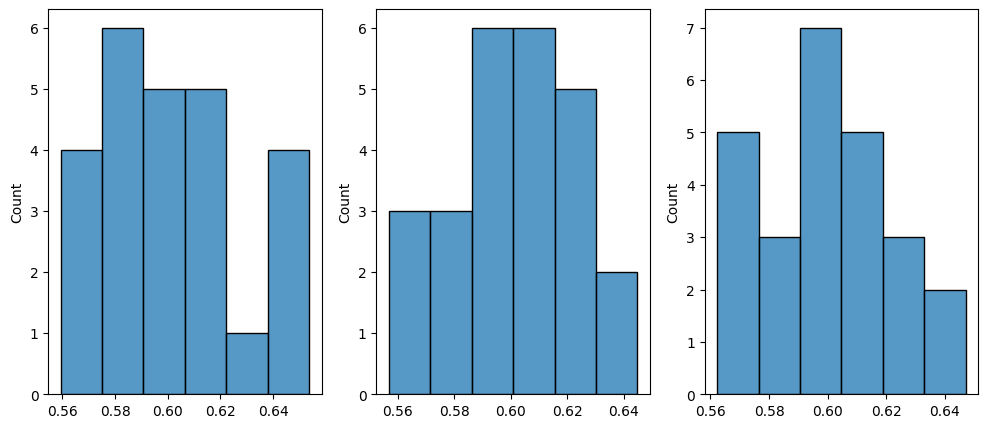

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, roc_auc_scores in zip(
    axes, [original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores], strict=True
):
    sns.histplot(roc_auc_scores, ax=ax)

In [16]:
print(stats.kruskal(original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores))

combinations = list(
    itertools.combinations(
        (
            ('Original', original_roc_auc_scores),
            ('Untrained', untrained_roc_auc_scores),
            ('Trained', trained_roc_auc_scores),
        ),
        2,
    )
)

adj_alpha_level = SIGNIFICANCE_LEVEL / len(combinations)

print()
print('Post-hoc:')
for (label1, group1), (label2, group2) in combinations:
    stat, p_val = stats.ranksums(group1, group2)

    print(f'{label1: <15}{label2: <15}{stat: .2f}      {p_val: .2e}      significant? {p_val < adj_alpha_level}')

KruskalResult(statistic=0.05322105263158505, pvalue=0.9737404139471852)

Post-hoc:
Original       Untrained      -0.03       9.77e-01      significant? False
Original       Trained         0.15       8.84e-01      significant? False
Untrained      Trained         0.24       8.08e-01      significant? False
